In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("/home/student/Downloads/ds-ev-range-analysis/data/EV_Cleaned_2025.csv")
df.head()

,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url,cargo_volume_l_original,cargo_volume_l_clean
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...,185,185.0
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...,185,185.0
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...,360,360.0
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...,360,360.0
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5,496,496.0


In [3]:
df.describe()

,top_speed_kmh,battery_capacity_kWh,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,length_mm,width_mm,height_mm,cargo_volume_l_clean
count,478.000000,478.000000,276.000000,471.000000,478.000000,478.000000,478.000000,477.000000,452.000000,478.000000,478.000000,478.000000,478.000000,474.000000
mean,185.487448,74.043724,485.293478,498.012739,162.903766,393.179916,6.882636,125.008386,1052.261062,5.263598,4678.506276,1887.359833,1601.125523,493.860759
std,34.252773,20.331058,1210.819733,241.461128,34.317532,103.287335,2.730696,58.205012,737.851774,1.003961,369.210573,73.656807,130.754851,187.005674
min,125.000000,21.300000,72.000000,113.000000,109.000000,135.000000,2.200000,29.000000,0.000000,2.000000,3620.000000,1610.000000,1329.000000,151.000000
25%,160.000000,60.000000,150.000000,305.000000,143.000000,320.000000,4.800000,80.000000,500.000000,5.000000,4440.000000,1849.000000,1514.000000,385.000000
50%,180.000000,76.150000,216.000000,430.000000,155.000000,397.500000,6.600000,113.000000,1000.000000,5.000000,4720.000000,1890.000000,1596.000000,470.000000
75%,201.000000,90.600000,324.000000,679.000000,177.750000,470.000000,8.200000,150.000000,1600.000000,5.000000,4961.000000,1939.000000,1665.000000,544.500000
max,325.000000,118.000000,7920.000000,1350.000000,370.000000,685.000000,19.100000,281.000000,2500.000000,9.000000,5908.000000,2080.000000,1986.000000,1410.000000


In [6]:
df.select_dtypes(include="number").corr()

,top_speed_kmh,battery_capacity_kWh,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,fast_charging_power_kw_dc,towing_capacity_kg,seats,length_mm,width_mm,height_mm,cargo_volume_l_clean
top_speed_kmh,1.000000,0.708486,0.361792,0.805513,0.171242,0.732130,-0.823443,0.771810,0.231041,-0.315572,0.443686,0.535850,-0.462712,-0.160174
battery_capacity_kWh,0.708486,1.000000,0.214515,0.756932,0.383607,0.880433,-0.643716,0.728066,0.451132,0.013413,0.689293,0.731496,-0.055999,0.122163
number_of_cells,0.361792,0.214515,1.000000,0.164120,-0.077907,0.311014,-0.254122,0.094389,0.070286,0.030315,0.181904,0.205763,-0.132658,0.090176
torque_nm,0.805513,0.756932,0.164120,1.000000,0.370422,0.651651,-0.787623,0.656593,0.352548,-0.162736,0.508932,0.572241,-0.195872,-0.037816
efficiency_wh_per_km,0.171242,0.383607,-0.077907,0.370422,1.000000,0.022943,-0.066512,0.182031,0.250221,0.522634,0.644838,0.573535,0.512614,0.405396
range_km,0.732130,0.880433,0.311014,0.651651,0.022943,1.000000,-0.712486,0.720932,0.333962,-0.248784,0.496867,0.521392,-0.413798,-0.065701
acceleration_0_100_s,-0.823443,-0.643716,-0.254122,-0.787623,-0.066512,-0.712486,1.000000,-0.628553,-0.286155,0.441376,-0.254990,-0.395869,0.494811,0.290790
fast_charging_power_kw_dc,0.771810,0.728066,0.094389,0.656593,0.182031,0.720932,-0.628553,1.000000,0.236353,-0.128115,0.474058,0.574412,-0.290376,-0.017317
towing_capacity_kg,0.231041,0.451132,0.070286,0.352548,0.250221,0.333962,-0.286155,0.236353,1.000000,0.151832,0.401418,0.468550,0.300047,0.154131
seats,-0.315572,0.013413,0.030315,-0.162736,0.522634,-0.248784,0.441376,-0.128115,0.151832,1.000000,0.458281,0.305574,0.697256,0.510118


Graph of EV driving range
First, we will see how the driving ranges of different electric vehicles are distributed.

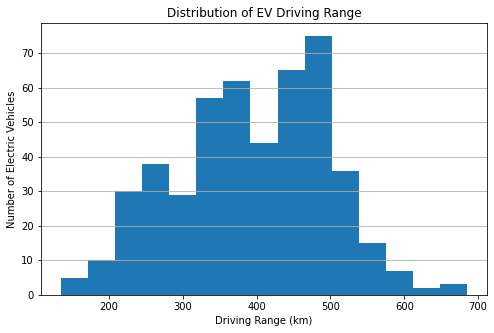

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(df["range_km"], bins=15)
plt.xlabel("Driving Range (km)")
plt.ylabel("Number of Electric Vehicles")
plt.title("Distribution of EV Driving Range")
plt.grid(axis="y")
plt.show()

Battery Capacity vs EV Driving Range
This graph helps us understand whether electric vehicles with larger battery capacities generally have greater driving ranges.

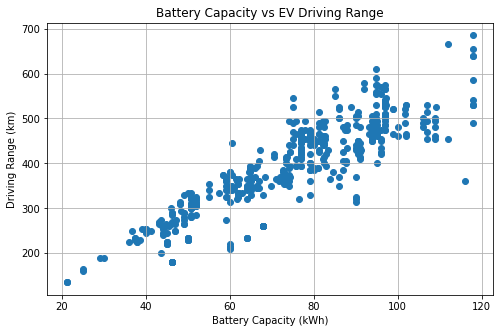

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df["battery_capacity_kWh"],df["range_km"])
plt.xlabel("Battery Capacity (kWh)")
plt.ylabel("Driving Range (km)")
plt.title("Battery Capacity vs EV Driving Range")
plt.grid(True)
plt.show()

Efficiency vs EV Driving Range
This graph helps us understand how vehicle energy efficiency is related to driving range.

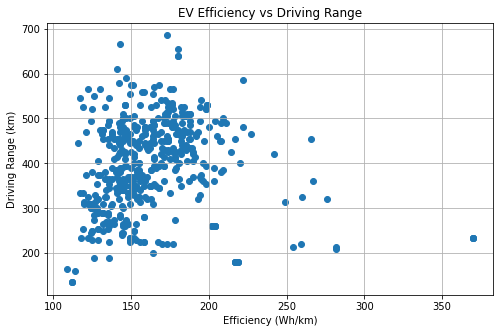

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df["efficiency_wh_per_km"],df["range_km"])
plt.xlabel("Efficiency (Wh/km)")
plt.ylabel("Driving Range (km)")
plt.title("EV Efficiency vs Driving Range")
plt.grid(True)
plt.show()

Top Speed vs EV Driving Range
This graph helps us understand whether an EV's maximum speed has any relationship with its driving range.

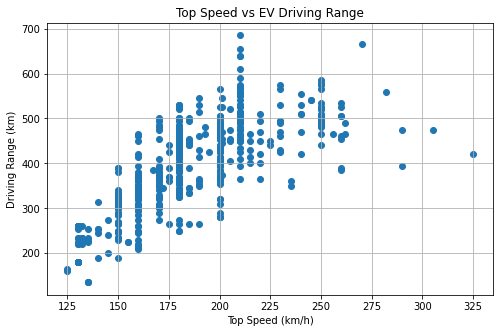

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(df["top_speed_kmh"],df["range_km"])
plt.xlabel("Top Speed (km/h)")
plt.ylabel("Driving Range (km)")
plt.title("Top Speed vs EV Driving Range")
plt.grid(True)
plt.show()

Correlation Heatmap
A correlation heatmap helps us understand how numerical columns in your dataset are related to one another.